In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
# Change the path if needed

df = pd.read_csv('Cafe.csv')

# Show First 5 Rows
print(df.head())

   Order_ID  Order_Date Order_Time Customer_ID Customer_Name  Customer_Age  \
0         1  02-02-2025   18:33:24    CUST0001      Michelle            59   
1         2  03-03-2025   12:59:00    CUST0002         Jorge            40   
2         3  26-02-2025   14:17:50    CUST0003      Victoria            32   
3         4  24-05-2025   11:13:53    CUST0004      Benjamin            43   
4         5  14-01-2025   23:03:52    CUST0005          Ryan            57   

   Gender  Customer_Type       City   Branch_Name  ...    Tax Total_Bill  \
0    Male        Regular  Bangalore  Coffee Point  ...   5.75     105.84   
1  Female        Regular     Nagpur    Cafe Bliss  ...  28.26     590.60   
2  Female        Student      Latur    Urban Brew  ...   5.48     108.62   
3  Female  Office Worker       Pune  Coffee Point  ...  43.98     917.09   
4  Female        Student      Latur    Cafe Bliss  ...  17.02     357.13   

   Payment_Method  Rating  Table_Number  Staff_Name  Preparation_Time_Min 

In [4]:
# Dataset Shape
print('Rows and Columns:', df.shape)

# Dataset Info
print(df.info())

# Missing Values
print(df.isnull().sum())

# Statistical Summary
print(df.describe())

Rows and Columns: (1000, 26)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               1000 non-null   int64  
 1   Order_Date             1000 non-null   str    
 2   Order_Time             1000 non-null   str    
 3   Customer_ID            1000 non-null   str    
 4   Customer_Name          1000 non-null   str    
 5   Customer_Age           1000 non-null   int64  
 6   Gender                 1000 non-null   str    
 7   Customer_Type          1000 non-null   str    
 8   City                   1000 non-null   str    
 9   Branch_Name            1000 non-null   str    
 10  Menu_Item              1000 non-null   str    
 11  Category               1000 non-null   str    
 12  Quantity               1000 non-null   int64  
 13  Price_Per_Item         1000 non-null   float64
 14  Subtotal               1000 non-null   

In [5]:
# Total Revenue
print('Total Revenue:', df['Total_Bill'].sum())

# Average Bill
print('Average Bill:', df['Total_Bill'].mean())

# Maximum Bill
print('Maximum Bill:', df['Total_Bill'].max())

Total Revenue: 850707.4400000001
Average Bill: 850.70744
Maximum Bill: 2661.27


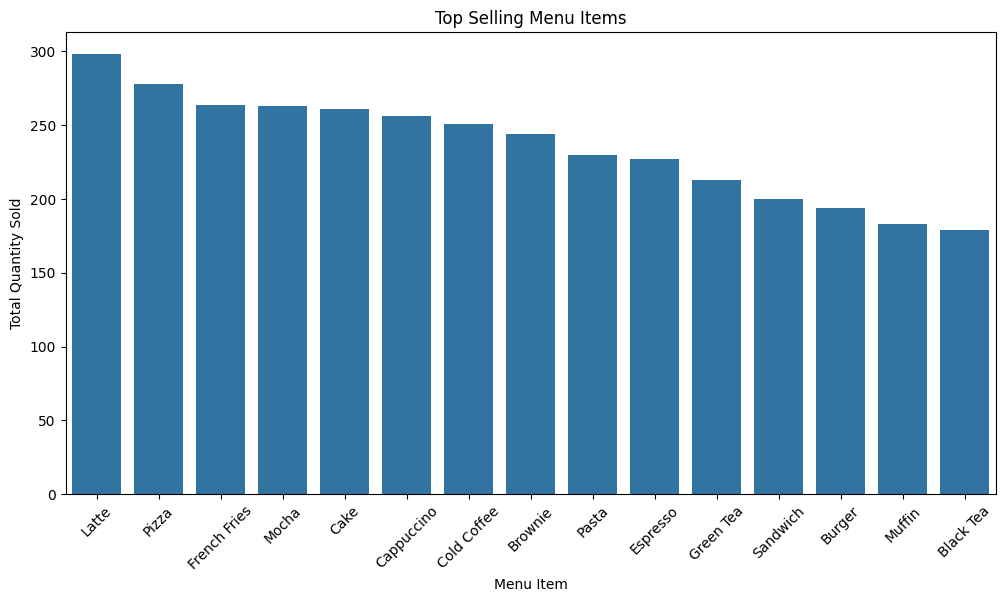

In [6]:
plt.figure(figsize=(12,6))

top_items = df.groupby('Menu_Item')['Quantity'].sum().sort_values(ascending=False)

sns.barplot(x=top_items.index, y=top_items.values)

plt.title('Top Selling Menu Items')
plt.xlabel('Menu Item')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.show()

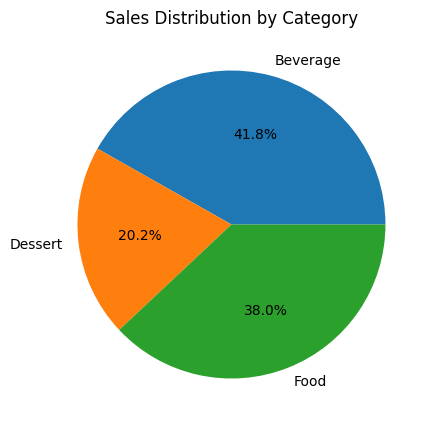

In [7]:
category_sales = df.groupby('Category')['Total_Bill'].sum()

plt.figure(figsize=(8,5))
plt.pie(category_sales, labels=category_sales.index, autopct='%1.1f%%')
plt.title('Sales Distribution by Category')
plt.show()

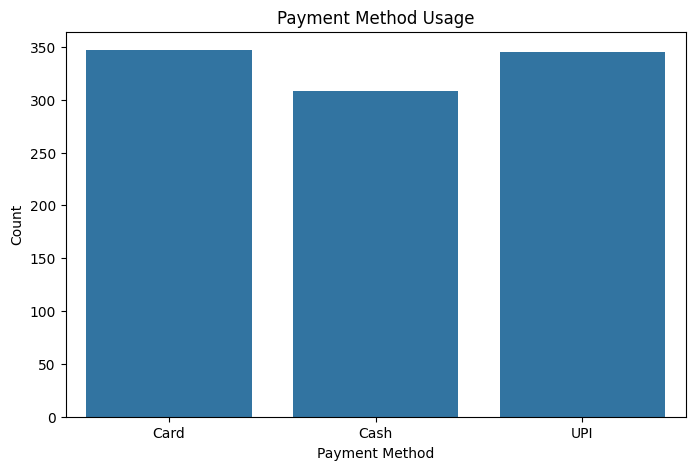

In [6]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Payment_Method')

plt.title('Payment Method Usage')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.show()

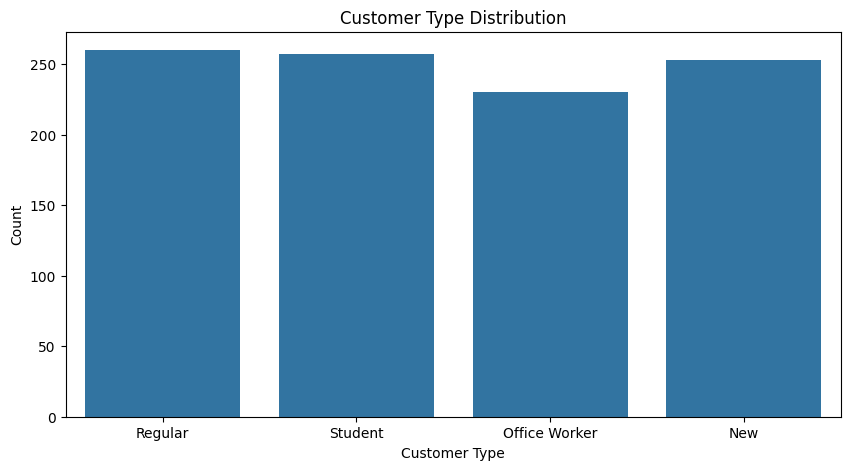

In [8]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='Customer_Type')

plt.title('Customer Type Distribution')
plt.xlabel('Customer Type')
plt.ylabel('Count')
plt.show()

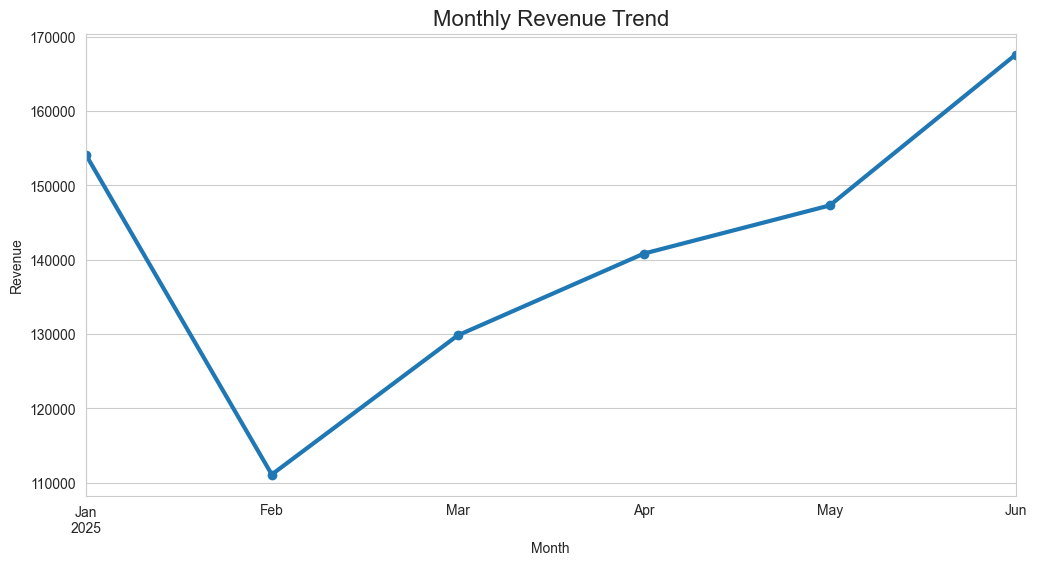

In [19]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], dayfirst=True)
df['Month'] = df['Order_Date'].dt.to_period('M')
monthly_sales = df.groupby('Month')['Total_Bill'].sum()
sns.set_style("whitegrid")
plt.figure(figsize=(12,6))
monthly_sales.plot(marker='o', linewidth=3)
plt.title('Monthly Revenue Trend', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.show()

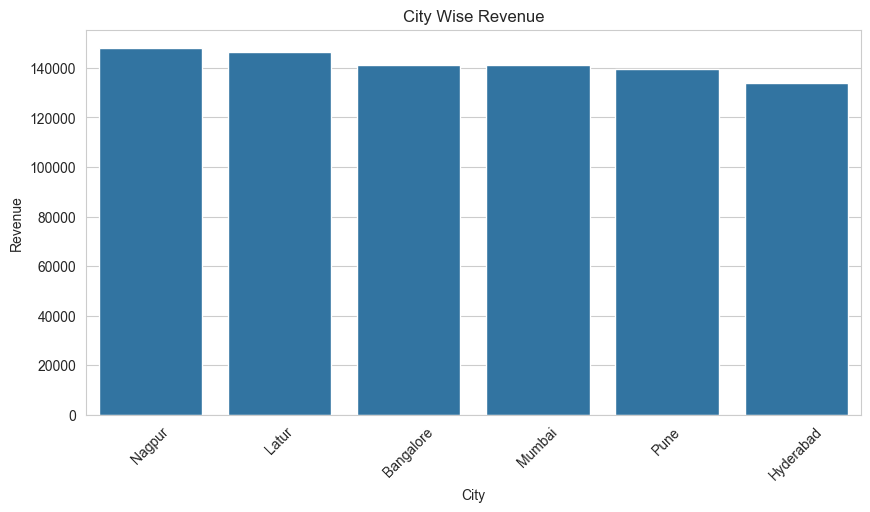

In [20]:
city_sales = df.groupby('City')['Total_Bill'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(x=city_sales.index, y=city_sales.values)

plt.title('City Wise Revenue')
plt.xlabel('City')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

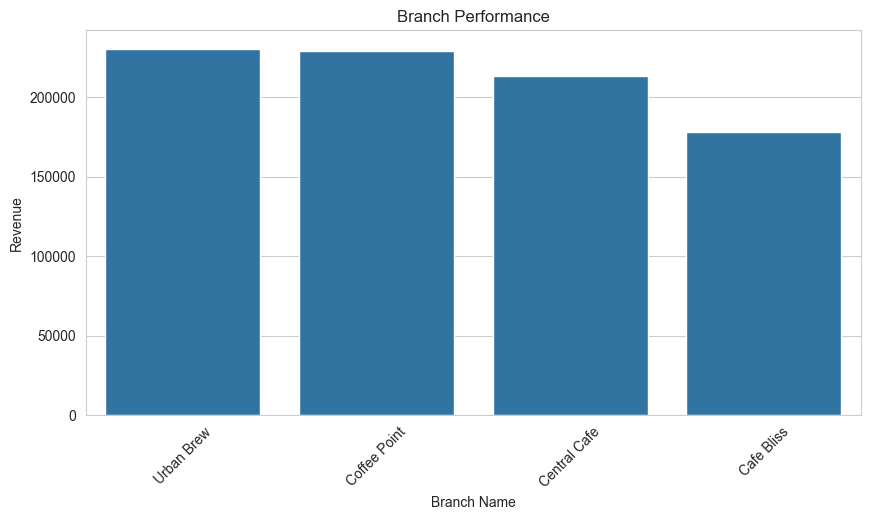

In [21]:
branch_sales = df.groupby('Branch_Name')['Total_Bill'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,5))

sns.barplot(x=branch_sales.index, y=branch_sales.values)

plt.title('Branch Performance')
plt.xlabel('Branch Name')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

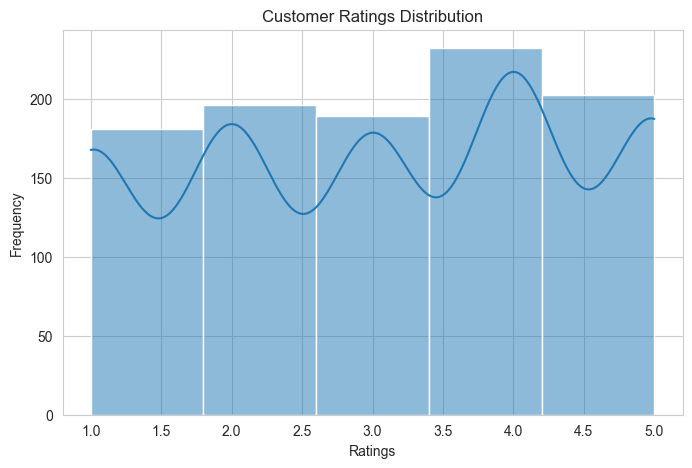

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(df['Rating'], bins=5, kde=True)

plt.title('Customer Ratings Distribution')
plt.xlabel('Ratings')
plt.ylabel('Frequency')
plt.show()

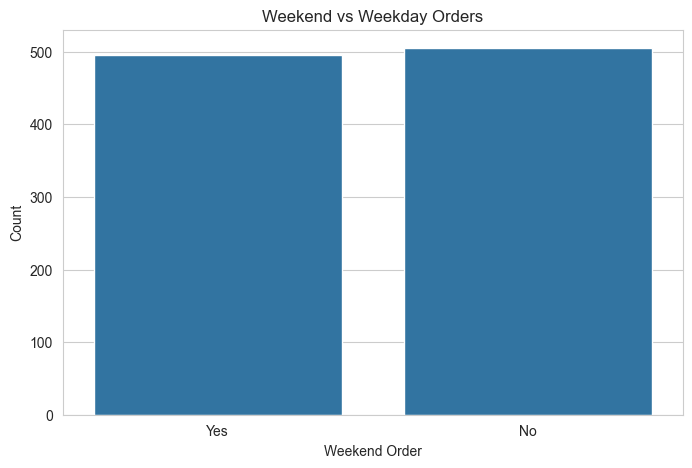

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Weekend_Order')

plt.title('Weekend vs Weekday Orders')
plt.xlabel('Weekend Order')
plt.ylabel('Count')
plt.show()

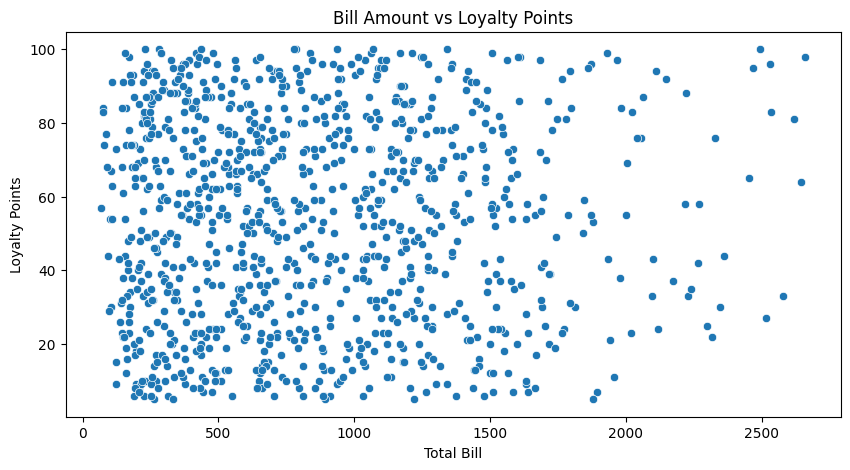

In [16]:
plt.figure(figsize=(10,5))

sns.scatterplot(data=df, x='Total_Bill', y='Loyalty_Points_Earned')

plt.title('Bill Amount vs Loyalty Points')
plt.xlabel('Total Bill')
plt.ylabel('Loyalty Points')
plt.show()

In [24]:
top_bills = df.sort_values(by='Total_Bill', ascending=False).head(10)

print(top_bills[['Customer_Name', 'Menu_Item', 'Total_Bill']])

    Customer_Name Menu_Item  Total_Bill
411        Ashley     Pizza     2661.27
594        Pamela     Pizza     2646.60
397       Matthew     Pizza     2619.57
970        Lauren     Pizza     2580.09
548     Christian     Pizza     2536.15
896        Angela     Pizza     2532.39
99         Amanda     Pizza     2515.97
113         Jacob     Pizza     2493.81
730       Gregory     Pizza     2468.96
56          Kelly     Pizza     2454.47


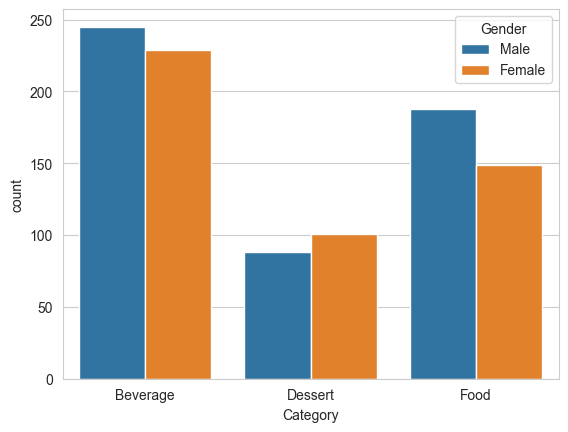

In [25]:
sns.countplot(x="Category",hue="Gender",data=df)
plt.show()

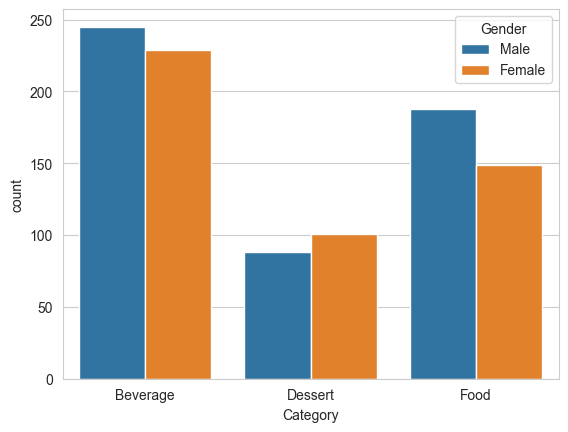

In [26]:
sns.countplot(x="Category",hue="Gender",data=df)
plt.show()